# 1. Why regularise? When ordinary least squares breaks

**Learning goals**
* See why OLS overfits when there are many predictors relative to observations.
* Understand the bias-variance trade-off that regularisation exploits.
* Meet the nowcasting problem in this project: 236 candidate predictors, 31 to 107 quarters of training data.

## The problem
OLS chooses coefficients $\hat\beta$ to minimise the residual sum of squares
$$\text{RSS}(\beta) = \sum_{i=1}^n (y_i - x_i^\top \beta)^2 .$$
It is unbiased, and among unbiased linear estimators it has the smallest variance (Gauss-Markov).
But unbiased is not the same as accurate. Its expected prediction error is roughly
$$\sigma^2\left(1 + \frac{p}{n}\right)$$
so every extra predictor adds variance. When $p \ge n$, $X^\top X$ is singular, infinitely many
coefficient vectors fit the training data perfectly, and the fitted model is pure memorisation.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## A simulation: train vs test error as predictors are added
Only the first 5 predictors matter; the rest are noise. n = 60 training rows.

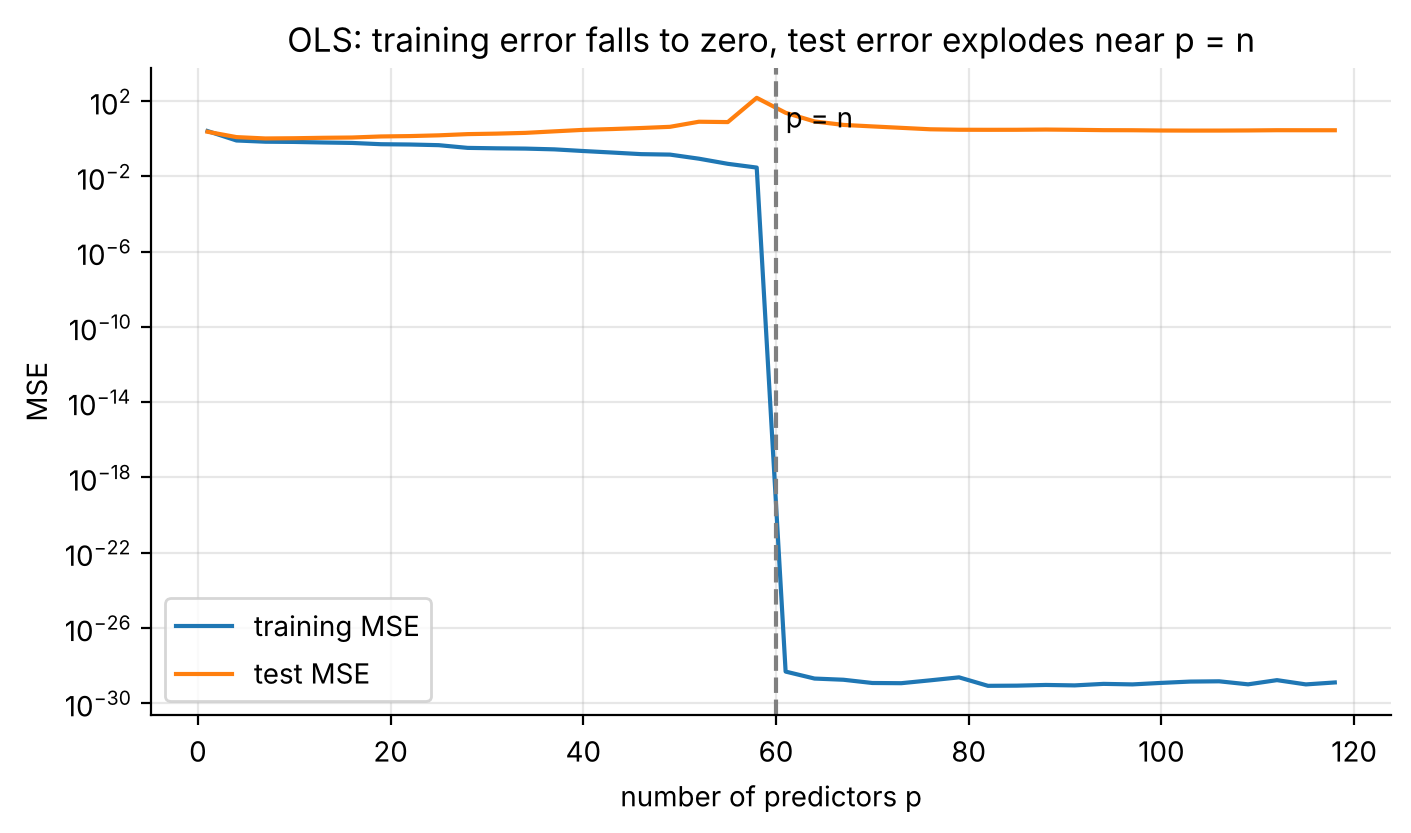

In [2]:
n, n_test, p_max, sigma = 60, 2000, 120, 1.0
beta = np.zeros(p_max); beta[:5] = [1.0, -0.8, 0.6, 0.5, -0.4]
Xall = rng.normal(size=(n + n_test, p_max))
yall = Xall @ beta + sigma * rng.normal(size=n + n_test)
Xtr, Xte, ytr, yte = Xall[:n], Xall[n:], yall[:n], yall[n:]

ps, tr_err, te_err = range(1, p_max + 1, 3), [], []
for p in ps:
    b, *_ = np.linalg.lstsq(np.c_[np.ones(n), Xtr[:, :p]], ytr, rcond=None)
    tr_err.append(np.mean((ytr - np.c_[np.ones(n), Xtr[:, :p]] @ b) ** 2))
    te_err.append(np.mean((yte - np.c_[np.ones(n_test), Xte[:, :p]] @ b) ** 2))

plt.plot(ps, tr_err, label="training MSE"); plt.plot(ps, te_err, label="test MSE")
plt.axvline(n, color="grey", ls="--"); plt.text(n + 1, 4, "p = n")
plt.yscale("log"); plt.xlabel("number of predictors p"); plt.ylabel("MSE"); plt.legend()
plt.title("OLS: training error falls to zero, test error explodes near p = n");

Training error falls monotonically; test error is lowest around the 5 true predictors, explodes as
$p \to n$ and, beyond $p = n$, the minimum-norm solution gets slightly better again (the "double
descent" curve). None of these OLS fits is as good as knowing which 5 matter.

## Bias-variance trade-off
For a new point, expected squared error = irreducible noise + bias² + variance.
Regularisation **deliberately adds a little bias** (shrinking coefficients towards zero) in exchange for
a large cut in variance. All the methods in this folder minimise
$$\text{RSS}(\beta) + \lambda \, \text{Penalty}(\beta)$$
and differ only in the penalty:

| Method | Penalty | Effect |
|---|---|---|
| Ridge | $\sum_j \beta_j^2$ | shrinks all coefficients, keeps all |
| Lasso | $\sum_j \lvert\beta_j\rvert$ | shrinks and sets some exactly to zero |
| Elastic net | $\alpha \sum \lvert\beta_j\rvert + \frac{1-\alpha}{2}\sum \beta_j^2$ | sparse, but keeps correlated groups together |
| Adaptive lasso | $\sum_j w_j \lvert\beta_j\rvert$ | less shrinkage on big effects |
| Group lasso | $\sum_g \sqrt{p_g}\lVert\beta_g\rVert_2$ | selects whole groups of variables |

$\lambda$ controls the trade-off: $\lambda=0$ is OLS, $\lambda\to\infty$ sets every coefficient to zero.

## The same problem in this project
Each nowcast uses 39 indicators x 6 monthly lags + 2 GDP lags = 236 features. Training samples run from 31 quarters (2006) to 107 (2026).

In [3]:
# The project's real data: the horizon-2 design (nowcast made at the end of the quarter)
from nowcast.features import build_all, main_spec
from nowcast.models import Standardiser
B = build_all([2])
X = B["X"][2]
X = X[[c for c in X.columns if main_spec(c)]]       # real-time output + other indicators
y = B["first"].reindex(X.index)                      # target: ONS's first published estimate
keep = y.notna() & ~X.index.isin(pd.period_range("2020Q1", "2021Q2", freq="Q"))
X, y = X[keep], y[keep]
names = list(X.columns)
print(X.shape, "quarters x features")

(108, 236) quarters x features


In [4]:
from nowcast.models import RidgeModel, time_folds
r = lambda a, b: np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2))
rows = []
for train_end, test in [("2007Q4", ("2008Q1", "2012Q4")), ("2015Q4", ("2016Q1", "2026Q2"))]:
    tr = X.index <= pd.Period(train_end, "Q")
    te = (X.index >= pd.Period(test[0], "Q")) & (X.index <= pd.Period(test[1], "Q"))
    st = Standardiser().fit(X[tr].values)
    Ztr, Zte = st.transform(X[tr].values), st.transform(X[te].values)
    A = lambda Z: np.c_[np.ones(len(Z)), Z]
    b, *_ = np.linalg.lstsq(A(Ztr), y[tr].values, rcond=None)
    rid = RidgeModel().fit(Ztr, y[tr].values, time_folds(tr.sum()))
    rows.append({"test period": f"{test[0]}-{test[1]}", "train quarters": int(tr.sum()),
                 "OLS in-sample": r(y[tr], A(Ztr) @ b), "OLS test": r(y[te], A(Zte) @ b),
                 "ridge test": r(y[te], rid.predict(Zte)),
                 "training mean test": r(y[te], np.full(te.sum(), y[tr].mean())),
                 "sd of target in test": y[te].std()})
pd.DataFrame(rows).set_index("test period").round(3)

,train quarters,OLS in-sample,OLS test,ridge test,training mean test,sd of target in test
test period,,,,,,
2008Q1-2012Q4,40,0.0,0.826,0.860,1.000,0.769
2016Q1-2026Q2,72,0.0,0.559,0.518,0.336,0.337


OLS fits the training quarters perfectly (in-sample RMSE ≈ 0) because there are more features than
quarters, and that perfect fit says nothing about out-of-sample accuracy. Out of sample, ridge
(penalty chosen by time-series cross-validation) is not better in every split. In 2008-12 it is
slightly worse than OLS, and both beat the average. In 2016-26 it beats OLS, but neither beats the
average. One split proves little. Across the main project's 361 real-time origins, ridge beats
minimum-norm OLS at every horizon (notebooks/04).

Notice the last two columns. Whether *any* model beats the simple average depends on how much GDP
moves in the test period. In a calm period the first estimate barely varies, and part of what does
vary is noise that ONS later revises away, so there is little left for indicators to explain. The
main project measures this properly with a full real-time backtest (notebook 04).

**Key takeaways**
* With $p$ close to or above $n$, OLS memorises the training data.
* Regularisation trades a little bias for much lower variance.
* The penalty's shape determines whether you get shrinkage, selection or group selection.